<a href="https://colab.research.google.com/github/sarabenzahra-afk/import_DS/blob/main/Movies_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DATA SCIENCE FINAL PROJECT**

# **PART A: Data Understanding**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns

The shape of the dataset, observations and variables:

In [4]:
# Read all sheets (3)
data = pd.read_excel("movies.xls", sheet_name=None)

for sheet_name, df in data.items():
    print(f"Sheet: {sheet_name} -> Shape: {df.shape}")

Sheet: 1900s -> Shape: (1338, 25)
Sheet: 2000s -> Shape: (2100, 25)
Sheet: 2010s -> Shape: (1604, 25)


We can concatenate the 3 sheets in one, since we have the same variables in all of them. I'll work on the first sheet and we can do the same for the others or for the whole dataset after the concatenation.

In [5]:
# Concatenate all of them in one
df_all = pd.concat(data.values(), ignore_index=True)

In [6]:
#check the results after concatenation
print("Shape du dataset : ", df_all.shape)
print("Number of observations : ", df_all.shape[0])
print("Number of variables : ", df_all.shape[1])

Shape du dataset :  (5042, 25)
Number of observations :  5042
Number of variables :  25



Identify variables: float64(13), int64(3), object(9)
1. Identifier
2. numerical
3. categorical
4. binary
5. target

In [8]:
df_all.info()
df_all.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5042 entries, 0 to 5041
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Title                        5042 non-null   object 
 1   Year                         4935 non-null   float64
 2   Genres                       5042 non-null   object 
 3   Language                     5029 non-null   object 
 4   Country                      5038 non-null   object 
 5   Content Rating               4740 non-null   object 
 6   Duration                     5028 non-null   float64
 7   Aspect Ratio                 4714 non-null   float64
 8   Budget                       4551 non-null   float64
 9   Gross Earnings               4159 non-null   float64
 10  Director                     4938 non-null   object 
 11  Actor 1                      5035 non-null   object 
 12  Actor 2                      5029 non-null   object 
 13  Actor 3           

,Title,Year,Genres,Language,Country,Content Rating,Duration,Aspect Ratio,Budget,Gross Earnings,...,Facebook Likes - Actor 1,Facebook Likes - Actor 2,Facebook Likes - Actor 3,Facebook Likes - cast Total,Facebook likes - Movie,Facenumber in posters,User Votes,Reviews by Users,Reviews by Crtiics,IMDB Score
0,Intolerance: Love's Struggle Throughout the Ages,1916.0,Drama|History|War,NaN,USA,Not Rated,123.0,1.33,385907.0,NaN,...,436.0,22.0,9.0,481,691,1.0,10718,88.0,69.0,8.0
1,Over the Hill to the Poorhouse,1920.0,Crime|Drama,NaN,USA,NaN,110.0,1.33,100000.0,3000000.0,...,2.0,2.0,0.0,4,0,1.0,5,1.0,1.0,4.8
2,The Big Parade,1925.0,Drama|Romance|War,NaN,USA,Not Rated,151.0,1.33,245000.0,NaN,...,81.0,12.0,6.0,108,226,0.0,4849,45.0,48.0,8.3
3,Metropolis,1927.0,Drama|Sci-Fi,German,Germany,Not Rated,145.0,1.33,6000000.0,26435.0,...,136.0,23.0,18.0,203,12000,1.0,111841,413.0,260.0,8.3
4,Pandora's Box,1929.0,Crime|Drama|Romance,German,Germany,Not Rated,110.0,1.33,NaN,9950.0,...,426.0,20.0,3.0,455,926,1.0,7431,84.0,71.0,8.0


In [9]:
#number of unique values to detect the identifier variable
df_all.nunique().sort_values()

,0
Content Rating,18
Facenumber in posters,19
Aspect Ratio,22
Language,46
Country,65
IMDB Score,78
Year,91
Duration,191
Facebook Likes - Director,435
Budget,439


In [11]:
# The identifier : Title

n_rows = len(df_all)
identifier_vars = []
potential_identifier_vars = []

for col in df_all.columns:
  n_unique = df_all[col].nunique(dropna=True)
  unique_ratio = n_unique / len(df_all)
  if unique_ratio == 1.0:
        identifier_vars.append(col)
  elif unique_ratio >= 0.95:
        potential_identifier_vars.append(col)

print("Perfect identifiers :", identifier_vars)
print("Potentiel identifiers :", potential_identifier_vars)

Perfect identifiers : []
Potentiel identifiers : ['Title', 'User Votes']


In [12]:
# numerical, categorical and binary variables:

numerical_vars = df_all.select_dtypes(include=["number"]).columns.tolist()
categorical_vars = df_all.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
binary_vars = [col for col in df_all.columns if df_all[col].nunique() == 2]
print("Numerical variables:", len(numerical_vars), numerical_vars)
print("Categorical variables:", len(categorical_vars), categorical_vars)
print("Binary variables:", len(binary_vars), binary_vars)

Numerical variables: 16 ['Year', 'Duration', 'Aspect Ratio', 'Budget', 'Gross Earnings', 'Facebook Likes - Director', 'Facebook Likes - Actor 1', 'Facebook Likes - Actor 2', 'Facebook Likes - Actor 3', 'Facebook Likes - cast Total', 'Facebook likes - Movie', 'Facenumber in posters', 'User Votes', 'Reviews by Users', 'Reviews by Crtiics', 'IMDB Score']
Categorical variables: 9 ['Title', 'Genres', 'Language', 'Country', 'Content Rating', 'Director', 'Actor 1', 'Actor 2', 'Actor 3']
Binary variables: 0 []


we propose as **target** variable **IMDB score**

**Inconsistencies:**

* Facebook Likes (Director, Actors), Facenumber in posters and  Reviews by ( Users, Crtiics) : float64-> int64
* Duration : int64 -> float64
* year : float64 -> integer(date)


In [13]:
df_all.dtypes

,0
Title,object
Year,float64
Genres,object
Language,object
Country,object
Content Rating,object
Duration,float64
Aspect Ratio,float64
Budget,float64
Gross Earnings,float64


Class distribution of the target variable: IMDB Score

In [14]:
print(df_all["IMDB Score"].value_counts())

IMDB Score
6.7    223
6.6    201
7.2    195
6.5    186
6.4    185
      ... 
9.2      1
9.3      1
1.6      1
1.7      1
9.5      1
Name: count, Length: 78, dtype: int64


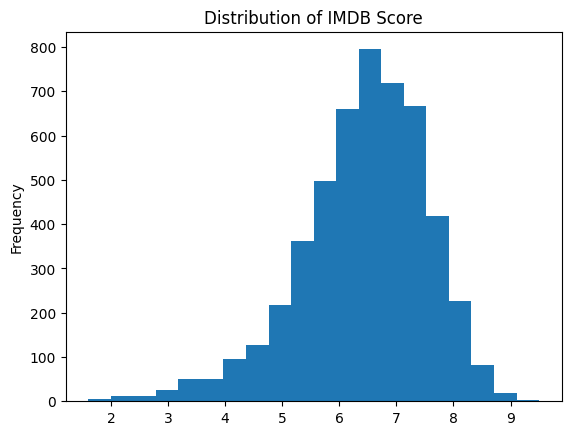

In [15]:
df_all["IMDB Score"].plot(kind="hist", bins=20)
plt.title("Distribution of IMDB Score")
plt.show()

In [23]:
#skewed negatively : mean < median < mode

print(df_all["IMDB Score"].describe())
print("Median =", df_all["IMDB Score"].median())
print("Mode =", df_all["IMDB Score"].mode())

count    5042.000000
mean        6.442007
std         1.125189
min         1.600000
25%         5.800000
50%         6.600000
75%         7.200000
max         9.500000
Name: IMDB Score, dtype: float64
Median = 6.6
Mode = 0    6.7
Name: IMDB Score, dtype: float64


In [28]:

Q1 = df_all["IMDB Score"].quantile(0.25)
Q2 = df_all["IMDB Score"].quantile(0.50)
Q3 = df_all["IMDB Score"].quantile(0.75)
IQR = Q3 - Q1
l_bound= Q1 - 1.5 * IQR
u_bound= Q3 + 1.5 * IQR
print("Q1=",Q1,"Q2=",Q2,"Q3=",Q3, "l_bound=", l_bound, "u_bound=", u_bound)
outliers_IMDB = df_all[(df_all["IMDB Score"]<l_bound) | (df_all["IMDB Score"]> u_bound)]

Q1= 5.8 Q2= 6.6 Q3= 7.2 l_bound= 3.6999999999999993 u_bound= 9.3



*  50% of the movies (median) scores is above 6.6 and the most scores are close to the mean (std=1.1)

*   The mean is almost equal to the median so the data is skewed a bit

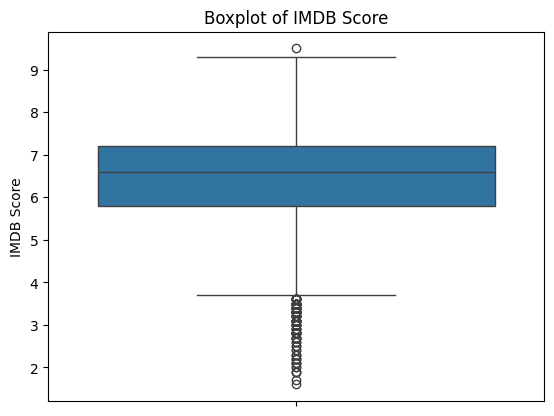

In [20]:
sns.boxplot(df_all["IMDB Score"])
plt.title("Boxplot of IMDB Score")
plt.show()

For the class distribution, we discretize the target variable (into categories):
*   low for poorly rated movies
*   medium for moderately rated movies
*   high for highly rated movies

This transforms the regression problem (predicting a continuous score) into a classification problem (predicting "low"/"medium"/"high").

In [29]:
df_all["target_class"] = pd.cut(
    df_all["IMDB Score"],
    bins=[0, 5, 7, 10],
    labels=["low", "medium", "high"],
    include_lowest=True
)

After classification, Dataset is still not balanced (skewed left). We have very few poorly rated movies comparing to the moderatly and highly rated.

In [30]:
print(df_all["target_class"].value_counts())

target_class
medium    2925
high      1593
low        524
Name: count, dtype: int64


# **PART B : Data Cleaning & Preprocessing**

Variables that contain missing values and their percentages

In [39]:
# Missing values
missing_values= df_all.isnull().sum()
missing_percent= df_all.isnull().sum()/ n_rows * 100
sum_m=pd.DataFrame({
    "missing_values":missing_values,
    "missing_percent":missing_percent})
sum_m= sum_m[sum_m["missing_values"] > 0]
print(sum_m)

                           missing_values  missing_percent
Year                                  107         2.122174
Language                               13         0.257834
Country                                 4         0.079334
Content Rating                        302         5.989687
Duration                               14         0.277668
Aspect Ratio                          328         6.505355
Budget                                491         9.738199
Gross Earnings                        883        17.512892
Director                              104         2.062674
Actor 1                                 7         0.138834
Actor 2                                13         0.257834
Actor 3                                22         0.436335
Facebook Likes - Director             104         2.062674
Facebook Likes - Actor 1                7         0.138834
Facebook Likes - Actor 2               13         0.257834
Facebook Likes - Actor 3               22         0.4363

**Appropriate treatment strategy for missing values**


* Drop rows where we have many missing values, lets choose 8 in our case (13rows)
* Impute missing values in :'Aspect Ratio', 'Gross Earnings', 'Budget', 'Facebook Likes','Reviews by Crtiics' with the mediane
* Replace (Content Rating, Language, Country) with 'Unknown'

In [41]:
#delete (or drop)
df_to_delete = df_all[df_all.isnull().sum(axis=1) >=8]
print("Number of rows to delete",len(df_to_delete ))

Number of rows to delete 13


In [42]:
#keep
df1 = df_all[df_all.isnull().sum(axis=1) < 8].copy()
print("Number of rows",len(df1))

Number of rows 5029


In [45]:
df1.isnull().sum()

,0
Title,0
Year,99
Genres,0
Language,11
Country,2
Content Rating,290
Duration,14
Aspect Ratio,320
Budget,483
Gross Earnings,872


In [83]:
# impute missing values in numeric columns with the column median
cols_to_impute = ['Aspect Ratio', 'Gross Earnings', 'Budget', 'Facebook Likes - Actor 3','Facebook Likes - Director', 'Reviews by Crtiics','Year']
df2 = df1.copy()
for col in cols_to_impute:
    median_value = df2[col].median()
    df2[col] = df2[col].fillna(median_value)

In [84]:
#check if there is any missing value in those columns
print(df2[cols_to_impute].isnull().sum())

Aspect Ratio                 0
Gross Earnings               0
Budget                       0
Facebook Likes - Actor 3     0
Facebook Likes - Director    0
Reviews by Crtiics           0
Year                         0
dtype: int64


In [85]:
# impute missing values in categorical columns with "Unknown"
cols_to_replace = ['Content Rating', 'Language', 'Country', 'Actor 3', 'Director']
df3=df2.copy()
df3[cols_to_replace] = df3[cols_to_replace].fillna("Unknown")

In [86]:
#check if there is any missing value
print(df3[cols_to_replace].isnull().sum())

Content Rating    0
Language          0
Country           0
Actor 3           0
Director          0
dtype: int64


Number of duplicate records: 45,
They should be removed because it's redandancy, no need to have the same information twice.

In [87]:
# Duplicates
print("Number of duplicate records : ",(df3.duplicated().sum()))

Number of duplicate records :  45


In [88]:
# Remove the exact duplicates
df_clean = df3.drop_duplicates().copy()

In [89]:
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Remaining duplicates :", df_clean.duplicated().sum())

Remaining missing values: 57
Remaining duplicates : 0


Detect potential outliers in numerical variables using:
* Boxplots
* IQR method

In [90]:
# Outlier detection (IQR method + boxplots)
outlier_cols = ["Duration", "Budget", "Gross Earnings", "User Votes",
                 "Facebook likes - Movie", "Facebook Likes - cast Total", "IMDB Score"]

outlier_summary = {}
for col in outlier_cols:
  q1 = df_clean[col].quantile(0.25)
  q3 = df_clean[col].quantile(0.75)
  iqr = q3 - q1
  lb= q1 - 1.5 * iqr
  ub= q3 + 1.5 * iqr
  n_out = ((df_clean[col] < lb) | (df_clean[col] > ub)).sum()
  outlier_summary[col] = {"Q1": q1, "Q3": q3, "IQR": iqr, "lower": lb, "upper": ub,
                             "number of outliers": n_out, "pct_outliers": round(n_out/len(df_clean)*100, 2)}

                                    Q1           Q3          IQR  \
Duration                          93.0       118.00        25.00   
Budget                       7000000.0  40000000.00  33000000.00   
Gross Earnings               8369142.5  51477958.75  43108816.25   
User Votes                      8682.0     96410.25     87728.25   
Facebook likes - Movie             0.0      3000.00      3000.00   
Facebook Likes - cast Total     1413.5     13770.00     12356.50   
IMDB Score                         5.8         7.20         1.40   

                                    lower         upper  number of outliers  \
Duration                     5.550000e+01  1.555000e+02               235.0   
Budget                      -4.250000e+07  8.950000e+07               428.0   
Gross Earnings              -5.629408e+07  1.161412e+08               468.0   
User Votes                  -1.229104e+05  2.280026e+05               462.0   
Facebook likes - Movie      -4.500000e+03  7.500000e+03     

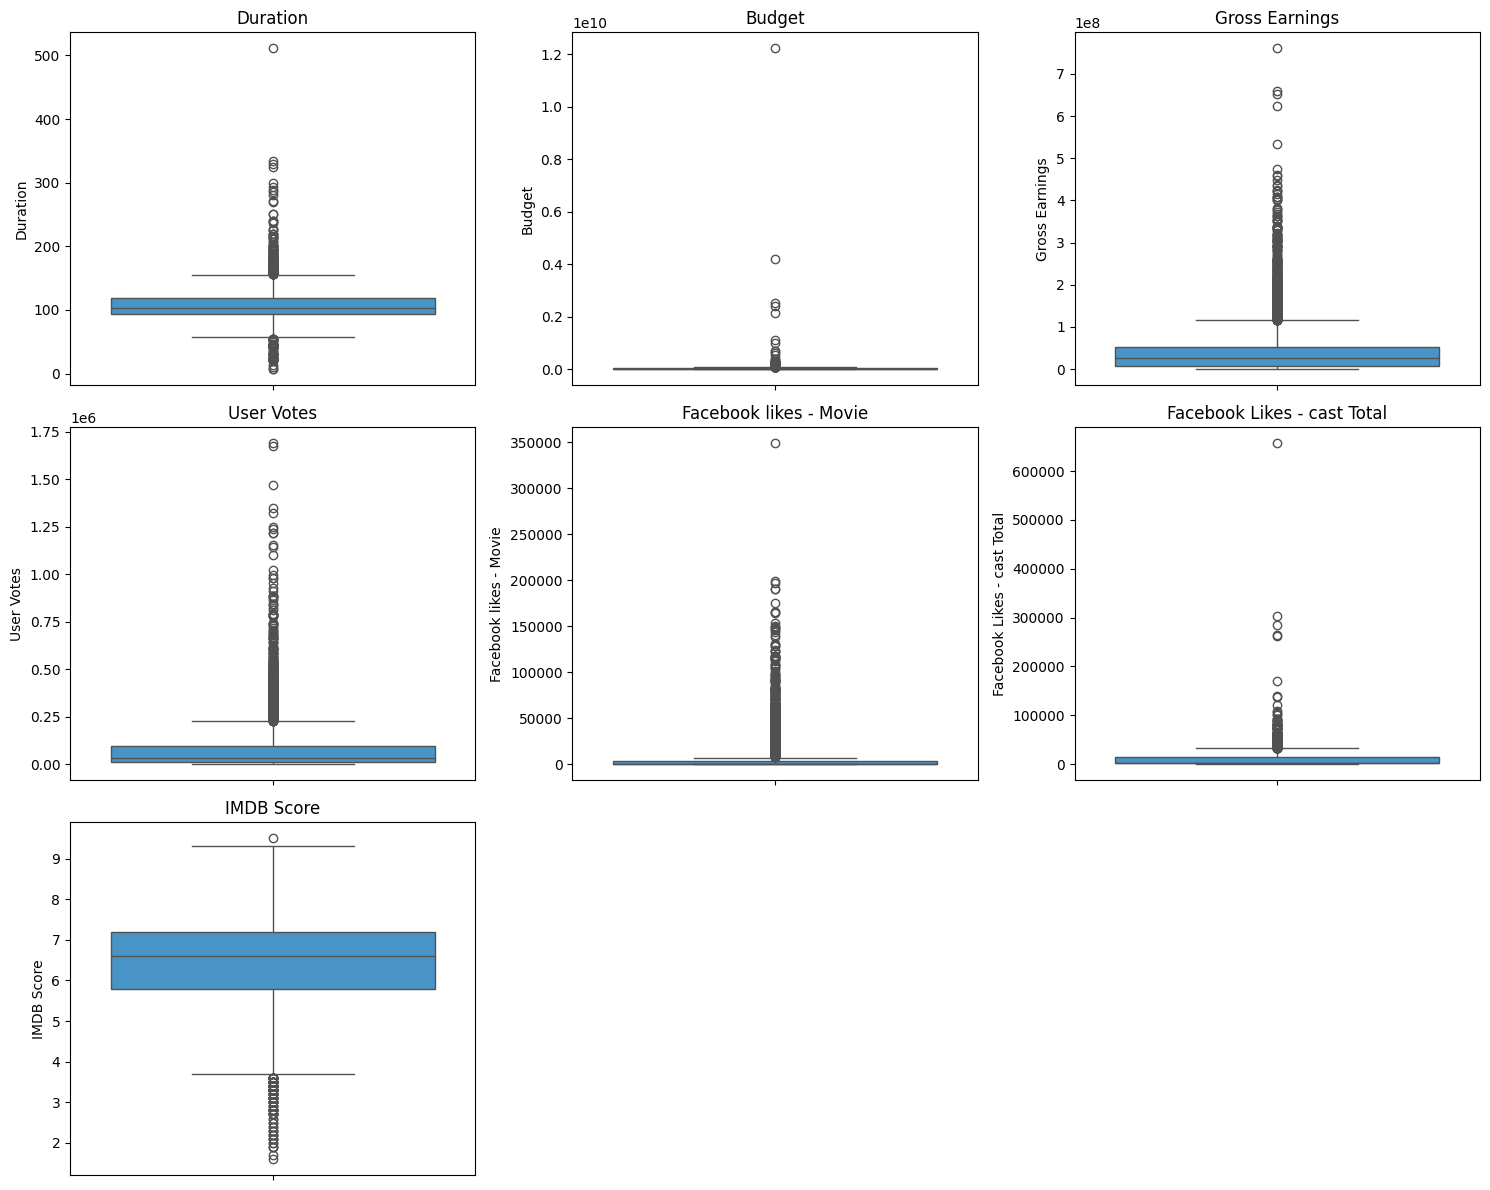

In [91]:
#list of outlier metrics into a clean DataFrame and transposes it
outlier_df = pd.DataFrame(outlier_summary).T
print(outlier_df)

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, outlier_cols):
    sns.boxplot(y=df_clean[col], ax=ax, color="#3498db")
    ax.set_title(col)
for ax in axes.flat[len(outlier_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("boxplots_outliers.png", dpi=110)
plt.show()
plt.close()

Toutes les variables (sauf IMDB Score) montrent le même profil : une boîte fine écrasée près de 0, surmontée d'un nuage dense de points au-dessus — signe d'une distribution très asymétrique, tirée par une minorité de films "à succès" (effet blockbuster).

Convert all variables to appropriate data types:
* less memory and faster groupby operations
* correct statistical behaviour ( columns are treated differently depending on their dtype)
* expose hidden data quality issues (numeric value stuck as float because few missing values)
*  avoid wrong results

In [97]:
# dtype conversion : Converting all variables to appropriate data types

df_clean["Content Rating"] = df_clean["Content Rating"].astype("category")
df_clean["Language"] = df_clean["Language"].astype("category")
df_clean["Country"] = df_clean["Country"].astype("category")
df_clean["Year"] = df_clean["Year"].astype(int)
df_clean["Genres_list"] = df_clean["Genres"].str.split("|")
for c in ["Facebook Likes - Actor 3", "Reviews by Crtiics"]:
    df_clean[c] = df_clean[c].round().astype(int)  # now safe: no more NaNs
print(df_clean.dtypes[["Content Rating", "Language", "Country", "Year",
                        "Facebook Likes - Actor 3", "Reviews by Crtiics"]])
df_clean.to_excel("df_partB.xlsx", index=False)

Content Rating              category
Language                    category
Country                     category
Year                           int64
Facebook Likes - Actor 3       int64
Reviews by Crtiics             int64
dtype: object


# **PART C : Exploratory Data Analysis**

In [98]:
# Descriptive statistics
desc = df_clean[numerical_vars].describe().T
desc["skew"] = df_clean[numerical_vars].skew()
print(desc.round(2))

                              count         mean           std      min  \
Year                         4984.0      2002.51  1.236000e+01  1916.00   
Duration                     4970.0       107.33  2.513000e+01     7.00   
Aspect Ratio                 4984.0         2.23  1.350000e+00     1.18   
Budget                       4984.0  37893014.97  1.969834e+08   218.00   
Gross Earnings               4984.0  44402144.61  6.241455e+07   162.00   
Facebook Likes - Director    4984.0       677.28  2.797610e+03     0.00   
Facebook Likes - Actor 1     4982.0      6568.24  1.507284e+04     0.00   
Facebook Likes - Actor 2     4979.0      1644.79  4.033020e+03     0.00   
Facebook Likes - Actor 3     4984.0       639.55  1.641820e+03     0.00   
Facebook Likes - cast Total  4984.0      9702.90  1.818425e+04     0.00   
Facebook likes - Movie       4984.0      7508.25  1.931380e+04     0.00   
Facenumber in posters        4971.0         1.37  2.010000e+00     0.00   
User Votes               

Calculate correlation coefficients to identify linear relationships between numerical variables and find potential multicollinearity.

                             Year  Duration  Aspect Ratio  Budget  \
Year                         1.00     -0.13          0.11    0.04   
Duration                    -0.13      1.00         -0.09    0.07   
Aspect Ratio                 0.11     -0.09          1.00   -0.00   
Budget                       0.04      0.07         -0.00    1.00   
Gross Earnings               0.04      0.23         -0.01    0.11   
Facebook Likes - Director   -0.07      0.16         -0.02    0.02   
Facebook Likes - Actor 1     0.08      0.09         -0.02    0.02   
Facebook Likes - Actor 2     0.10      0.13         -0.01    0.05   
Facebook Likes - Actor 3     0.09      0.12         -0.00    0.05   
Facebook Likes - cast Total  0.11      0.12         -0.02    0.04   
Facebook likes - Movie       0.22      0.19          0.02    0.06   
Facenumber in posters        0.06      0.02          0.01   -0.02   
User Votes                   0.01      0.31         -0.02    0.08   
Reviews by Users            -0.00 

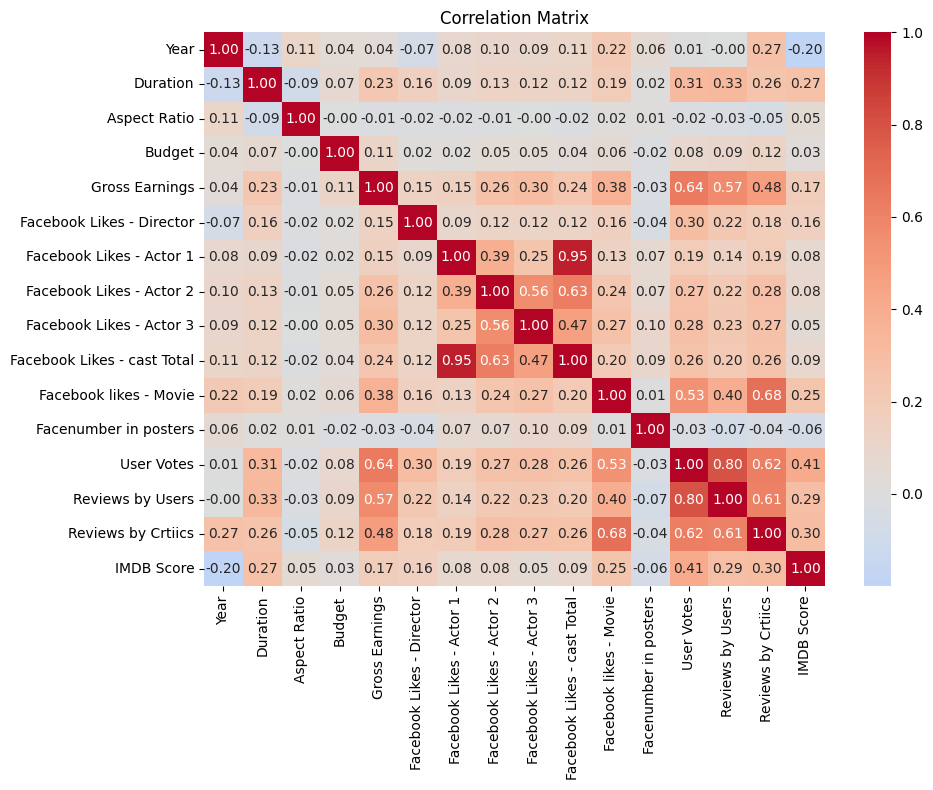

In [100]:
# correlation matrix (Pearson)
corr=df_clean.corr(numeric_only=True)
print(corr.round(2))
#Draw Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [101]:
# Flag high multicollinearity pairs (|r| > 0.7, excluding diagonal)
print("\nHighly correlated pairs (|r| > 0.7):")
pairs = corr.abs().unstack().sort_values(ascending=False)
pairs = pairs[(pairs < 1) & (pairs > 0.7)]
seen = set()
for (a, b), v in pairs.items():
    if (b, a) in seen:
        continue
    seen.add((a, b))
    print(f"  {a}  <->  {b} : r = {corr.loc[a,b]:.2f}")


Highly correlated pairs (|r| > 0.7):
  Facebook Likes - Actor 1  <->  Facebook Likes - cast Total : r = 0.95
  Reviews by Users  <->  User Votes : r = 0.80


1. Facebook Likes - Actor 1 ↔ Facebook Likes - cast Total : r = 0.95
 ces deux variables évoluent presque parfaitement ensemble — quand les likes de l'Actor 1 augmentent, le total des likes du cast augmente presque proportionnellement.
 2. Reviews by Users  <->  User Votes : r = 0.80 Ce que ça signifie : les films qui reçoivent beaucoup de votes reçoivent aussi beaucoup de critiques écrites par les utilisateurs, et vice versa.

Segment data using grouping tools combined with aggregations like mean or sum: analyze average IMDB score by Content Rating

In [102]:
# Grouping / aggregation: average IMDB score & Gross Earnings by Content Rating
grp = df_clean.groupby("Content Rating", observed=True).agg(
    avg_score=("IMDB Score", "mean"),
    avg_gross=("Gross Earnings", "mean"),
    n=("Title", "count")
).sort_values("avg_score", ascending=False)
print(grp.round(2))


                avg_score    avg_gross     n
Content Rating                              
TV-MA                8.29  22888347.42    19
TV-Y                 7.40  25528495.00     1
TV-PG                7.35  25528495.00    13
Approved             7.33  32930542.96    55
TV-14                7.27  25528495.00    29
TV-Y7                7.20  25528495.00     1
Passed               7.17  20686842.44     9
TV-G                 6.92  25528495.00    10
GP                   6.92  28573745.83     6
Unrated              6.90  13500487.35    60
M                    6.84  40338877.00     5
Not Rated            6.63  14011321.91   116
NC-17                6.54   7484245.29     7
G                    6.53  73814509.05   112
R                    6.52  29416710.48  2098
X                    6.50  20244123.15    13
Unknown              6.40  20263965.16   288
PG                   6.30  66918205.37   698
PG-13                6.26  63599068.06  1444


Ça regroupe tous les films par catégorie de classification (Content Rating), puis calcule pour chaque groupe : le score IMDB moyen, le revenu brut moyen, et le nombre de films (n) dans ce groupe. C'est une façon de résumer comment la classification est liée à la qualité perçue (score) et à la performance commerciale (revenus).

* boxplot qui compare la distribution des scores IMDB pour les 6 classifications de films les plus courantes (les rares comme X, TV-Y sont exclues car pas assez de films pour être fiables).
* tableau de stats (médiane, écart-type, min, max) pour ces mêmes 6 catégories, trié du score médian le plus haut au plus bas.
* Le but : voir si le type de classification (G, PG, PG-13, R, etc.) est lié à la qualité perçue du film (score IMDB)

/tmp/ipykernel_589/2013651510.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


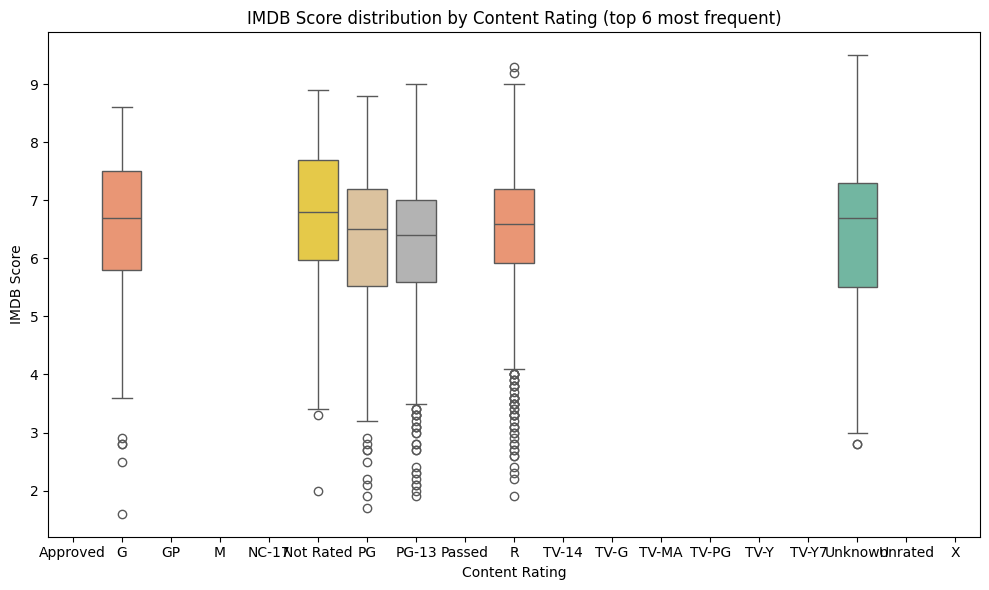

                median   std  min  max
Content Rating                        
Not Rated          6.8  1.34  2.0  8.9
G                  6.7  1.40  1.6  8.6
Unknown            6.7  1.29  2.8  9.5
R                  6.6  1.03  1.9  9.3
PG                 6.5  1.19  1.7  8.8
PG-13              6.4  1.09  1.9  9.0


In [141]:
import matplotlib.pyplot as plt
import seaborn as sns

# On garde seulement les 6 catégories de rating les plus fréquentes
# (sinon le graphique devient illisible avec trop de catégories rares)
top_ratings = df_clean["Content Rating"].value_counts().head(6).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=df_clean[df_clean["Content Rating"].isin(top_ratings)],
    x="Content Rating",
    y="IMDB Score",
    ax=ax,
    palette="Set2"
)
ax.set_title("IMDB Score distribution by Content Rating (top 6 most frequent)")
plt.tight_layout()
plt.savefig("boxplot_score_by_rating.png", dpi=110)
plt.show()

# Statistiques associées : médiane, écart-type, min, max par catégorie
rating_stats = (
    df_clean[df_clean["Content Rating"].isin(top_ratings)]
    .groupby("Content Rating", observed=True)["IMDB Score"]
    .agg(["median", "std", "min", "max"])
    .sort_values("median", ascending=False)
)
print(rating_stats.round(2))

Measure the strength and scale of association between categorical variables(Cramer's V) to check if variables are independent(Chi2).

In [112]:
from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np

def cramers_v(x, y):
    ct = pd.crosstab(x, y)

    # Get all outputs from the chi-square test
    chi2, p, dof, expected = chi2_contingency(ct)

    n = ct.values.sum()
    phi2 = chi2 / n
    r, k = ct.shape
    v = np.sqrt(phi2 / min(k - 1, r - 1))

    return v, p

NameError: name 'p' is not defined

In [127]:
# Association between categorical variables: Cramér's V
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    phi2 = chi2 / n
    r, k = ct.shape
    return np.sqrt(phi2 / min(k-1, r-1))

cat_pairs = [("Content Rating", "Language"), ("Content Rating", "Country"), ("Language", "Country")]
for a, b in cat_pairs:
    v = cramers_v(df_clean[a], df_clean[b])

    print(f"\n{a} vs {b}")
    print(f"Cramér's V: {v:.3f}")


Content Rating vs Language
Cramér's V: 0.123

Content Rating vs Country
Cramér's V: 0.151

Language vs Country
Cramér's V: 0.640


Correlation matrix for numerical variables:

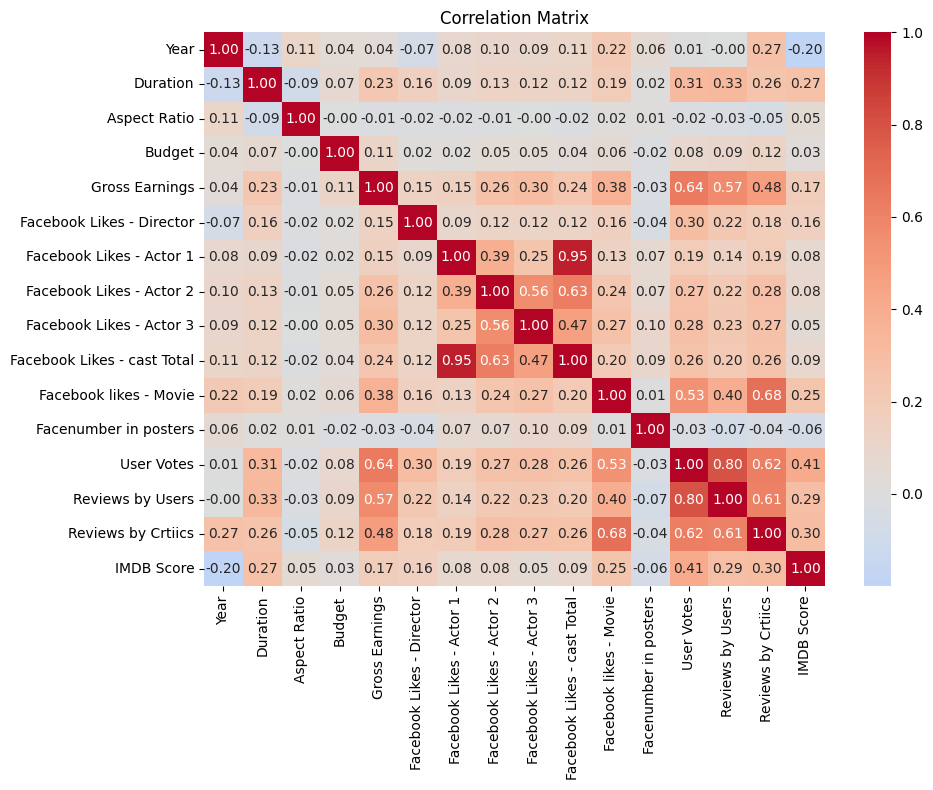

In [106]:
#Draw Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

* Correlation does not imply causation :  even if two variables are statistically associated, it does not mean that one variable causes the other. The observed relationship may be due to a third (confounding) variable, coincidence, or indirect effects.

Examples:
* User Votes and IMDb Score: A positive correlation does not mean that receiving more votes causes a movie to have a higher IMDb score.
* Duration and Gross Earnings : A correlation  does not mean that making a movie longer increases its earnings.

# **PART D : Feature Engineering & Transformation**

New relevant features and their expected impact on dataset informativeness

In [133]:
df_fe = df_clean.copy()

# 1) Profit & profit margin -> direct financial-success signal, distinct from
#    IMDB score (a film can be a critical hit and a commercial flop or v.v.)
df_fe["Profit"] = df_fe["Gross Earnings"] - df_fe["Budget"]
df_fe["ROI"] = df_fe["Profit"] / df_fe["Budget"].replace(0, np.nan)

# 2) Total popularity/buzz score combining cast + movie Facebook likes and
#    critic/user engagement -> into a single overall buzz score: single "hype" index,
df_fe["Buzz_Score"] = (df_fe["Facebook likes - Movie"] + df_fe["Facebook Likes - cast Total"] + df_fe["User Votes"] / 100)

# 3) Movie age (years since release, relative to dataset's latest year) ->
#    lets models capture "classic effect" (older films sometimes rated higher)
df_fe["Movie_Age"] = df_fe["Year"].max() - df_fe["Year"]

Examine skewness in numerical variables

Skewness AVANT transformation :
Budget                    50.40
Gross Earnings             3.46
User Votes                 4.03
Facebook likes - Movie     5.08
dtype: float64

Skewness APRÈS transformation log1p :
Budget_log       -1.27
Gross_log        -1.61
User_Votes_log   -0.96
FB_Movie_log      0.19
dtype: float64


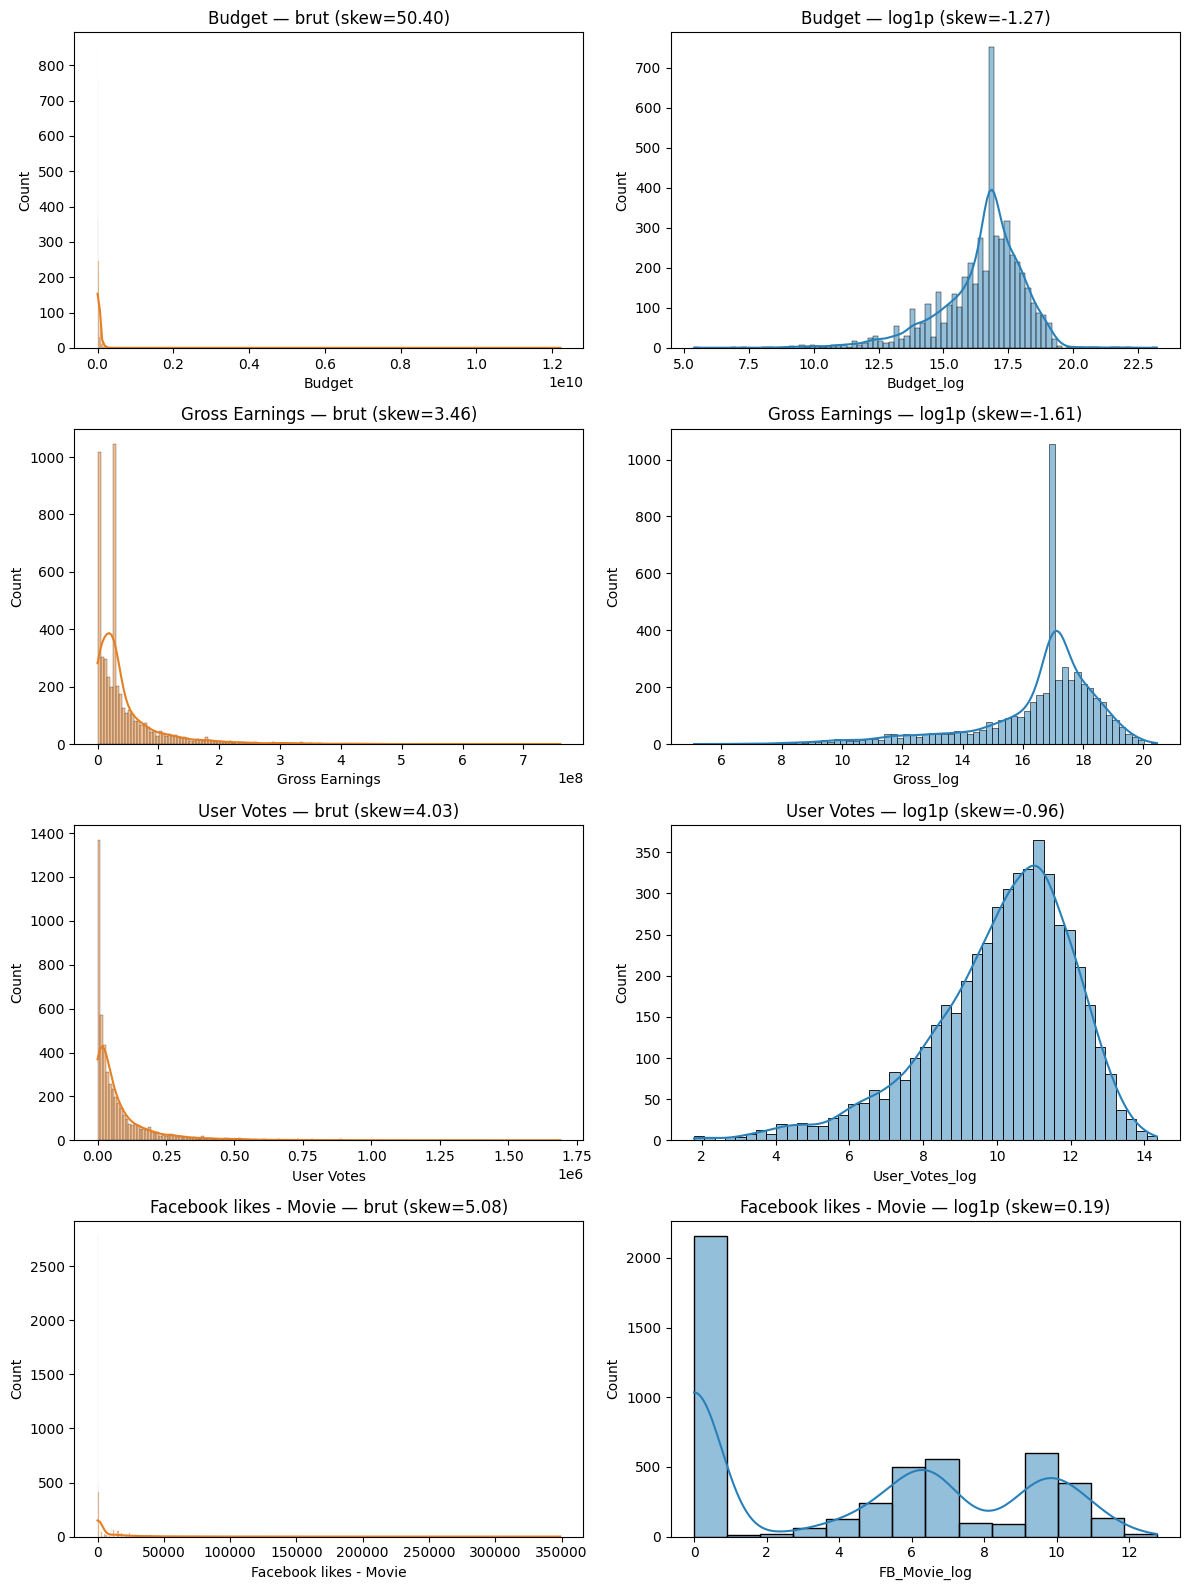

In [144]:
# Skewness & transformation
skew_before = df_fe[["Budget", "Gross Earnings", "User Votes", "Facebook likes - Movie"]].skew()
print("Skewness AVANT transformation :")
print(skew_before.round(2))

df_fe["Budget_log"] = np.log1p(df_fe["Budget"])
df_fe["Gross_log"] = np.log1p(df_fe["Gross Earnings"].clip(lower=0))
df_fe["User_Votes_log"] = np.log1p(df_fe["User Votes"])
df_fe["FB_Movie_log"] = np.log1p(df_fe["Facebook likes - Movie"])

skew_after = df_fe[["Budget_log", "Gross_log", "User_Votes_log", "FB_Movie_log"]].skew()
print("\nSkewness APRÈS transformation log1p :")
print(skew_after.round(2))

# Graphique avant / après, côte à côte pour chaque variable ---
variables = [
    ("Budget", "Budget_log"),
    ("Gross Earnings", "Gross_log"),
    ("User Votes", "User_Votes_log"),
    ("Facebook likes - Movie", "FB_Movie_log"),
]

fig, axes = plt.subplots(len(variables), 2, figsize=(12, 16))

for i, (raw, logc) in enumerate(variables):
    # Colonne de gauche : distribution brute
    sns.histplot(df_fe[raw], kde=True, ax=axes[i, 0], color="#e67e22")
    axes[i, 0].set_title(f"{raw} — brut (skew={df_fe[raw].skew():.2f})")

    # Colonne de droite : distribution après log1p
    sns.histplot(df_fe[logc], kde=True, ax=axes[i, 1], color="#2980b9")
    axes[i, 1].set_title(f"{raw} — log1p (skew={df_fe[logc].skew():.2f})")

plt.tight_layout()
plt.savefig("skew_before_after.png", dpi=110)
plt.show()

* Budget & Gross Earnings : le vrai problème n'est pas la transformation log, c'est le pic d'imputation par médiane qui fausse la distribution. Solution : utiliser une imputation plus fine (par genre/décennie) ou exclure les valeurs imputées de l'analyse de skew.
* User Votes : transformation réussie, exploitable telle quelle.
* Facebook likes - Movie : le skew de 0.19 est un faux positif — la vraie structure est bimodale (avec/sans Facebook), pas symétrique. Il faudrait peut-être créer une variable binaire séparée Has_Facebook_Presence (0/1) en plus du log, pour capturer cette césure historique.

# **PART E : Visualization & Analysis**

NameError: name 'FIG' is not defined

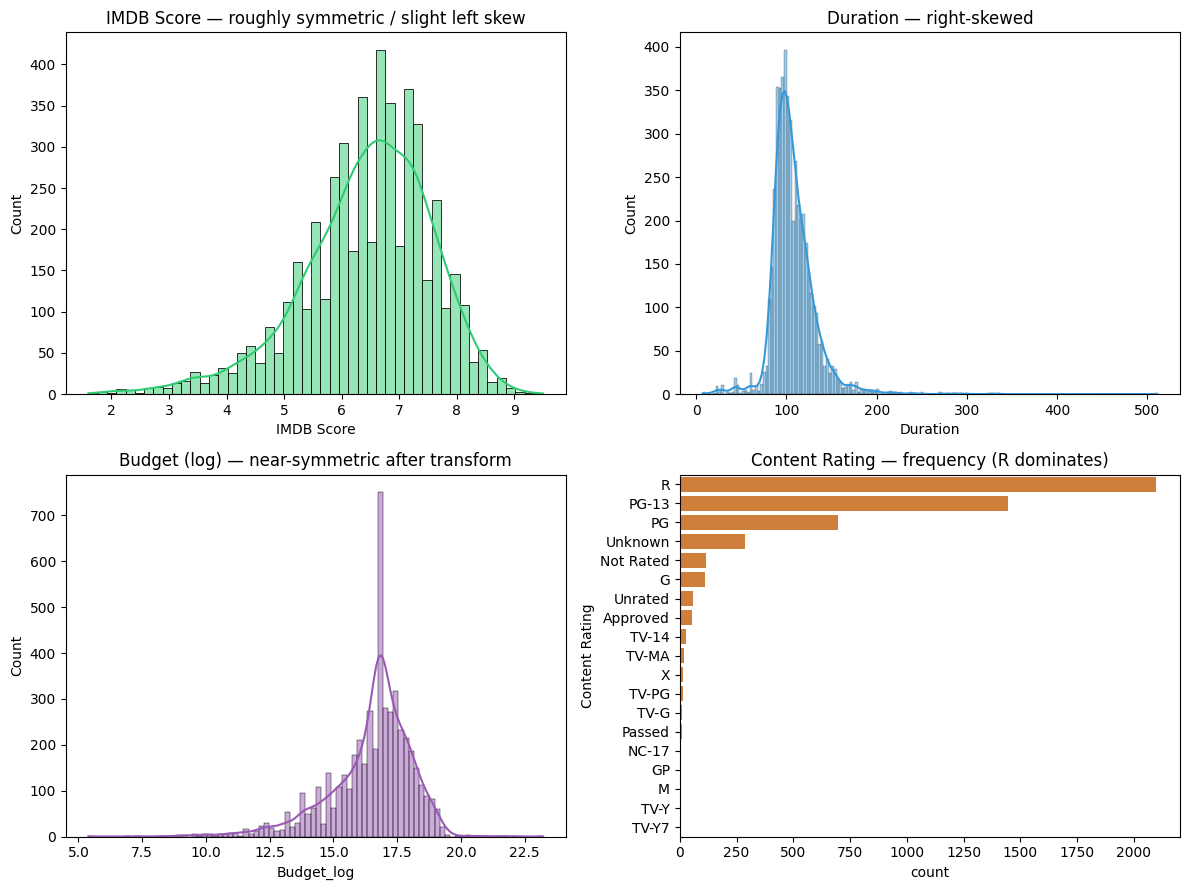

In [138]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.histplot(df_fe["IMDB Score"], kde=True, ax=axes[0,0], color="#2ecc71")
axes[0,0].set_title("IMDB Score — roughly symmetric / slight left skew")
sns.histplot(df_fe["Duration"], kde=True, ax=axes[0,1], color="#3498db")
axes[0,1].set_title("Duration — right-skewed")
sns.histplot(df_fe["Budget_log"], kde=True, ax=axes[1,0], color="#9b59b6")
axes[1,0].set_title("Budget (log) — near-symmetric after transform")
sns.countplot(y=df_fe["Content Rating"], order=df_fe["Content Rating"].value_counts().index, ax=axes[1,1], color="#e67e22")
axes[1,1].set_title("Content Rating — frequency (R dominates)")
plt.tight_layout()
plt.savefig(f"{FIG}/univariate.png", dpi=110)
plt.close()

skew_vals = df_fe[["IMDB Score", "Duration", "Budget", "Gross Earnings"]].skew()
print("\nSkewness recap for shape interpretation:")
print(skew_vals.round(2))
print("IMDB Score: |skew|<0.5 -> approximately symmetric.")
print("Duration, Budget, Gross Earnings: skew>1 -> strongly right-skewed (long tail of")
print("blockbuster budgets/runtimes/revenues).")